# <b>StaxioAI — GenLLM</b>

### Installing Libraries

In [1]:
!pip install -q \
    trl==0.11.1 \
    transformers==4.45.2 \
    datasets==3.0.1 \
    peft==0.13.2 \
    accelerate==1.0.1 \
    evaluate==0.4.3 \
    scikit-learn \
    pandas \
    numpy \
    torchmetrics

## Importing the Libraries

In [2]:
import torch
from torch.utils.data import Dataset
from tqdm import tqdm
import evaluate
from datasets import load_dataset
from transformers import AutoModelForCausalLM, AutoTokenizer
from peft import LoraConfig, TaskType, get_peft_model
from trl import SFTConfig, SFTTrainer

import matplotlib.pyplot as plt

In [3]:
device = 'cuda'

## 1. Dataset Preparation

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [26]:
dataset_path = '/content/drive/MyDrive/Staxio/Datasets/StaxioAI_GenLLM_dataset.jsonl'

In [27]:
dataset = load_dataset('json', data_files = dataset_path)
print(dataset)

Generating train split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['messages'],
        num_rows: 4000
    })
})


In [28]:
dataset = dataset.shuffle(seed = 42)

In [29]:
dataset['train'][2]

{'messages': [{'role': 'system',
   'content': 'You are StaxioAI, an internal AI assistant for Brightloop Software employees only.\nYour role is to help Admin, Finance Lead, and Internal Staff with information about subscriptions, customers, invoices, payments, and related policies.\nYou are strictly read-only. You cannot modify any records, issue refunds, change prices, or perform write operations.\nCustomers do not have access to you.\nBe professional, concise, and helpful. For general questions about yourself, answer clearly based on your capabilities.'},
  {'role': 'user', 'content': 'Yo'},
  {'role': 'assistant',
   'content': "Hello! I'm StaxioAI, ready to help with internal subscription and billing lookups. What do you need?"}]}

### Train - Test Split

In [30]:
dataset_split = dataset['train'].train_test_split(test_size = 0.05, seed = 42)
train_dataset = dataset_split['train']
test_dataset = dataset_split['test']

dataset_split

DatasetDict({
    train: Dataset({
        features: ['messages'],
        num_rows: 3800
    })
    test: Dataset({
        features: ['messages'],
        num_rows: 200
    })
})

### Tokenizer

In [32]:
tokenizer = AutoTokenizer.from_pretrained(model_name)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

In [33]:
def format_chat(example):
    return {
        "text": tokenizer.apply_chat_template(
            example['messages'],
            tokenize = False,
            add_generation_prompt = False
        )
    }

train_dataset = train_dataset.map(format_chat)
test_dataset = test_dataset.map(format_chat)

Map:   0%|          | 0/3800 [00:00<?, ? examples/s]

Map:   0%|          | 0/200 [00:00<?, ? examples/s]

## 2. Model

In [31]:
model_name = "Qwen/Qwen2.5-3B-Instruct"

In [34]:
model = AutoModelForCausalLM.from_pretrained(
    model_name,
    torch_dtype = torch.float16
)

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

model-00001-of-00002.safetensors:   0%|          | 0.00/3.97G [00:00<?, ?B/s]

model-00002-of-00002.safetensors:   0%|          | 0.00/2.20G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

## 3. Perform Fine-Tuning with LoRA

In [35]:
lora_config = LoraConfig(
    task_type = TaskType.CAUSAL_LM,
    r = 16,
    lora_alpha = 32,
    lora_dropout = 0.05,
    target_modules = [
        'q_proj',
        'k_proj',
        'v_proj',
        'o_proj',
        'gate_proj',
        'up_proj',
        'down_proj'
    ],
    bias = 'none'
)

### Wrapping Model with LoRA

In [36]:
model = get_peft_model(model, lora_config)

### SFT Config

In [37]:
from trl import SFTConfig

sft_config = SFTConfig(
    output_dir = '/content/drive/MyDrive/Staxio/Saved Checkpoints/',

    num_train_epochs = 2,

    per_device_train_batch_size = 1,
    per_device_eval_batch_size = 1,

    gradient_accumulation_steps = 8,

    learning_rate = 2e-4,

    fp16 = True,
    bf16 = False,

    logging_steps = 10,
    eval_steps = 100,
    save_steps = 100,

    evaluation_strategy = 'steps',
    save_strategy = 'steps',

    max_seq_length = 512,

    report_to = "none",

    seed = 42
)

/usr/local/lib/python3.13/dist-packages/transformers/training_args.py:1545: FutureWarning: `evaluation_strategy` is deprecated and will be removed in version 4.46 of 🤗 Transformers. Use `eval_strategy` instead
  warnings.warn(


### SFT Trainer

In [38]:
trainer = SFTTrainer(
    model = model,
    train_dataset = train_dataset,
    eval_dataset = test_dataset,
    tokenizer = tokenizer,
    dataset_text_field = 'text',
    args = sft_config
)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_deprecation.py:100: FutureWarning: Deprecated argument(s) used in '__init__': dataset_text_field. Will not be supported from version '1.0.0'.

Deprecated positional argument(s) used in SFTTrainer, please use the SFTConfig to set these arguments instead.
  warnings.warn(message, FutureWarning)
/usr/local/lib/python3.13/dist-packages/trl/trainer/sft_trainer.py:321: UserWarning: You passed a `dataset_text_field` argument to the SFTTrainer, the value you passed will override the one in the `SFTConfig`.
  warnings.warn(


Map:   0%|          | 0/3800 [00:00<?, ? examples/s]

Map:   0%|          | 0/200 [00:00<?, ? examples/s]

In [39]:
trainer.train()

Step,Training Loss,Validation Loss
100,0.088500,0.094139
200,0.077000,0.073871
300,0.065100,0.070115
400,0.064800,0.066776
500,0.063400,0.065673
600,0.048400,0.065783
700,0.058300,0.065095
800,0.058400,0.063999
900,0.053400,0.063195


TrainOutput(global_step=950, training_loss=0.10141094559117367, metrics={'train_runtime': 2719.2022, 'train_samples_per_second': 2.795, 'train_steps_per_second': 0.349, 'total_flos': 2.740890139341619e+16, 'train_loss': 0.10141094559117367, 'epoch': 2.0})

In [40]:
trainer.save_model(
    "/content/drive/MyDrive/Staxio/Saved Adapters/StaxioAI_v1"
)

tokenizer.save_pretrained(
    "/content/drive/MyDrive/Staxio/Saved Adapters/StaxioAI_v1"
)

('/content/drive/MyDrive/Staxio/Saved Adapters/StaxioAI_v1/tokenizer_config.json',
 '/content/drive/MyDrive/Staxio/Saved Adapters/StaxioAI_v1/special_tokens_map.json',
 '/content/drive/MyDrive/Staxio/Saved Adapters/StaxioAI_v1/vocab.json',
 '/content/drive/MyDrive/Staxio/Saved Adapters/StaxioAI_v1/merges.txt',
 '/content/drive/MyDrive/Staxio/Saved Adapters/StaxioAI_v1/added_tokens.json',
 '/content/drive/MyDrive/Staxio/Saved Adapters/StaxioAI_v1/tokenizer.json')

In [41]:
log_history_lora = trainer.state.log_history

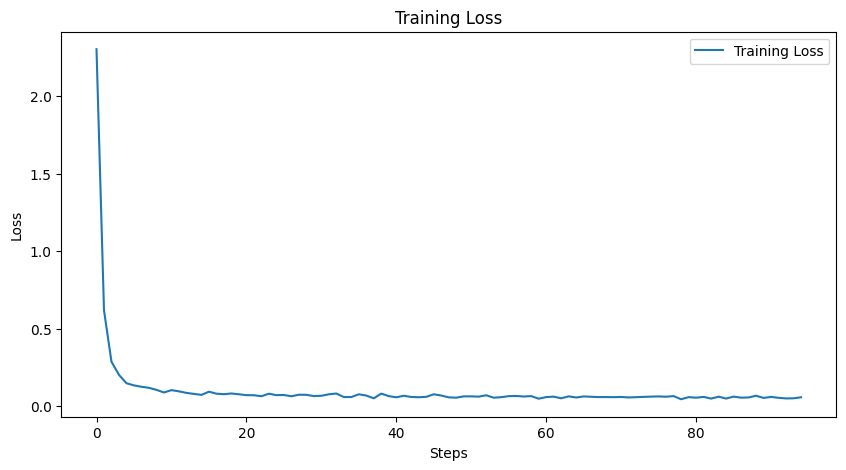

In [42]:
train_loss = [log['loss'] for log in log_history_lora if 'loss' in log]

plt.figure(figsize = (10, 5))
plt.plot(train_loss, label = 'Training Loss')

plt.xlabel('Steps')
plt.ylabel('Loss')
plt.title('Training Loss')
plt.legend()
plt.show()